# Supervised Classification: Model Comparison and Hyperparameter Tuning

**Goal:** Compare four classification models, tune their hyperparameters using stratified cross-validation, evaluate on a held-out test set, select a champion model using validation F1-score, and save the fitted pipeline.

**Dataset note:** `classification_modeling_dataset.csv` is a synthetic demonstration dataset. If your instructor requires a real-world dataset, replace it with an approved dataset before submission.

## How to run
1. Run each cell from top to bottom in Google Colab.
2. Upload `classification_modeling_dataset.csv` when prompted.
3. Wait for model tuning and evaluation to finish.
4. At the end, download the notebook and the saved `champion_model.joblib` file if required.

The target column is `churn` (0 = class 0, 1 = class 1). The model uses a preprocessing pipeline so imputation, scaling, and encoding are fitted within each cross-validation fold without leaking test data.

## 1. Imports and load the dataset

In [2]:
import io
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import files
uploaded = files.upload()
csv_name = next(name for name in uploaded if name.lower().endswith(".csv"))
df = pd.read_csv(io.BytesIO(uploaded[csv_name]))

print("Dataset shape:", df.shape)
display(df.head())
print("\\nData types:")
print(df.dtypes)
print("\\nMissing values:")
display(df.isnull().sum().sort_values(ascending=False))
print("\\nTarget distribution:")
display(df["churn"].value_counts())


Saving classification_modeling_dataset.csv to classification_modeling_dataset (1).csv
Dataset shape: (900, 12)


,age,monthly_spend,tenure_months,support_tickets,login_days_ago,usage_score,payment_delay_days,service_calls,plan_type,contract_type,region,churn
0,4.975050,NaN,-5.894184,-1.730094,1.276399,-0.329489,1.674860,2.680764,NaN,Monthly,South,1
1,0.880434,-0.411439,-0.754196,2.041100,-1.037606,0.659531,1.766512,2.989149,Basic,Monthly,East,0
2,-0.477506,-1.730415,0.916212,-0.033669,0.104011,NaN,0.738237,-2.021613,Premium,Monthly,North,0
3,-0.540635,-0.413839,0.613560,0.750471,0.278030,1.166371,0.530976,1.378734,Standard,NaN,East,0
4,0.562986,0.340977,-0.767920,0.347953,1.294736,NaN,-0.842433,2.998878,Basic,Two-Year,West,1


\nData types:
age                   float64
monthly_spend         float64
tenure_months         float64
support_tickets       float64
login_days_ago        float64
usage_score           float64
payment_delay_days    float64
service_calls         float64
plan_type              object
contract_type          object
region                 object
churn                   int64
dtype: object
\nMissing values:


,0
usage_score,50
monthly_spend,44
plan_type,44
tenure_months,40
contract_type,37
age,37
support_tickets,36
login_days_ago,0
service_calls,0
payment_delay_days,0


\nTarget distribution:


,count
churn,
0,605
1,295


## 2. Split data before fitting transformations

In [3]:
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

TARGET = "churn"
X = df.drop(columns=[TARGET])
y = df[TARGET].astype(int)

numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)


Training rows: 720
Testing rows: 180
Numeric features: ['age', 'monthly_spend', 'tenure_months', 'support_tickets', 'login_days_ago', 'usage_score', 'payment_delay_days', 'service_calls']
Categorical features: ['plan_type', 'contract_type', 'region']


## 3. Define four baseline model pipelines

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.ensemble import GradientBoostingClassifier

models = {
    "Logistic Regression": (
        LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42),
        {"model__C": [0.1, 1.0, 10.0]}
    ),
    "Random Forest": (
        RandomForestClassifier(class_weight="balanced", random_state=42),
        {"model__n_estimators": [100, 200], "model__max_depth": [None, 8]}
    ),
    "Gradient Boosting": (
        GradientBoostingClassifier(random_state=42),
        {"model__n_estimators": [100, 150], "model__learning_rate": [0.05, 0.1]}
    ),
    "Extra Trees": (
        ExtraTreesClassifier(class_weight="balanced", random_state=42),
        {"model__n_estimators": [100, 200], "model__max_depth": [None, 8]}
    )
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print("Models to compare:", list(models.keys()))


Models to compare: ['Logistic Regression', 'Random Forest', 'Gradient Boosting', 'Extra Trees']


## 4. Tune hyperparameters using GridSearchCV

In [5]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, ConfusionMatrixDisplay,
    confusion_matrix, RocCurveDisplay
)
from sklearn.base import clone

searches = {}
rows = []

for name, (estimator, param_grid) in models.items():
    pipe = Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("model", estimator)
    ])
    search = GridSearchCV(
        estimator=pipe,
        param_grid=param_grid,
        scoring="f1",
        cv=cv,
        n_jobs=-1,
        refit=True
    )
    search.fit(X_train, y_train)
    searches[name] = search
    rows.append({
        "Model": name,
        "Best CV F1": search.best_score_,
        "Best Parameters": search.best_params_
    })
    print(f"Finished: {name} | best CV F1 = {search.best_score_:.3f}")

tuning_results = pd.DataFrame(rows).sort_values("Best CV F1", ascending=False)
display(tuning_results)


Finished: Logistic Regression | best CV F1 = 0.613
Finished: Random Forest | best CV F1 = 0.734
Finished: Gradient Boosting | best CV F1 = 0.704
Finished: Extra Trees | best CV F1 = 0.654


,Model,Best CV F1,Best Parameters
1,Random Forest,0.733592,"{'model__max_depth': 8, 'model__n_estimators':..."
2,Gradient Boosting,0.704236,"{'model__learning_rate': 0.1, 'model__n_estima..."
3,Extra Trees,0.654401,"{'model__max_depth': 8, 'model__n_estimators':..."
0,Logistic Regression,0.612903,{'model__C': 10.0}


## 5. Evaluate each tuned model on the held-out test set

In [6]:
evaluation_rows = []
predictions = {}

for name, search in searches.items():
    best_model = search.best_estimator_
    y_pred = best_model.predict(X_test)
    y_prob = best_model.predict_proba(X_test)[:, 1]
    predictions[name] = (y_pred, y_prob)
    evaluation_rows.append({
        "Model": name,
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "Accuracy": accuracy_score(y_test, y_pred)
    })

comparison = pd.DataFrame(evaluation_rows).sort_values("F1-Score", ascending=False)
display(comparison.round(3))


,Model,Precision,Recall,F1-Score,ROC-AUC,Accuracy
1,Random Forest,0.841,0.627,0.718,0.876,0.839
3,Extra Trees,0.735,0.610,0.667,0.845,0.800
2,Gradient Boosting,0.786,0.559,0.653,0.868,0.806
0,Logistic Regression,0.487,0.627,0.548,0.703,0.661


## 6. ROC-AUC curves

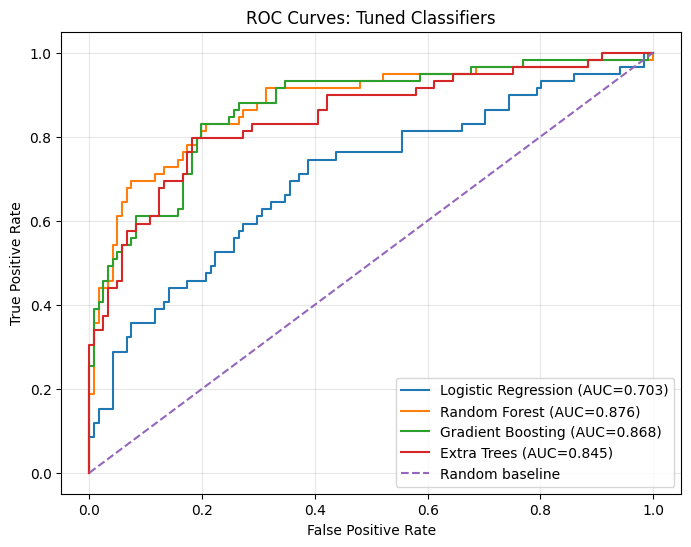

In [7]:
plt.figure(figsize=(8, 6))
for name, (y_pred, y_prob) in predictions.items():
    from sklearn.metrics import roc_curve, auc
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc(fpr, tpr):.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves: Tuned Classifiers")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


## 7. Confusion matrix and detailed report for the champion

Champion model: Random Forest
Best cross-validation F1: 0.734
\nClassification report:
              precision    recall  f1-score   support

           0       0.84      0.94      0.89       121
           1       0.84      0.63      0.72        59

    accuracy                           0.84       180
   macro avg       0.84      0.78      0.80       180
weighted avg       0.84      0.84      0.83       180



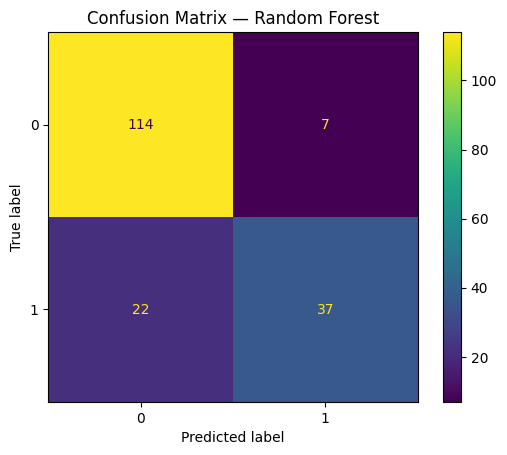

In [8]:
# Choose the champion using cross-validation F1-score, not test-set performance.
champion_name = max(searches, key=lambda name: searches[name].best_score_)
champion_model = searches[champion_name].best_estimator_
champion_pred = champion_model.predict(X_test)
champion_prob = champion_model.predict_proba(X_test)[:, 1]

print("Champion model:", champion_name)
print("Best cross-validation F1:", round(searches[champion_name].best_score_, 3))
print("\\nClassification report:")
print(classification_report(y_test, champion_pred, zero_division=0))

ConfusionMatrixDisplay.from_predictions(y_test, champion_pred)
plt.title(f"Confusion Matrix — {champion_name}")
plt.show()


## 8. Save the champion pipeline

In [9]:
import joblib

MODEL_PATH = "champion_model.joblib"
joblib.dump(champion_model, MODEL_PATH)
print("Saved model:", MODEL_PATH)

# In Google Colab, this downloads the fitted preprocessing + model pipeline.
files.download(MODEL_PATH)


Saved model: champion_model.joblib


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 9. Example prediction

In [10]:
# Example: predict the first row of the held-out test set.
sample = X_test.iloc[[0]]
print("Input row:")
display(sample)
print("Predicted class:", int(champion_model.predict(sample)[0]))
print("Probability of class 1:", round(float(champion_model.predict_proba(sample)[0, 1]), 3))


Input row:


,age,monthly_spend,tenure_months,support_tickets,login_days_ago,usage_score,payment_delay_days,service_calls,plan_type,contract_type,region
472,1.70458,2.510162,-2.577215,-1.807792,0.499189,-0.274802,-2.201243,2.407911,Basic,Monthly,West


Predicted class: 1
Probability of class 1: 0.748


## Conclusion

This notebook compares four supervised classification algorithms and tunes their hyperparameters using `GridSearchCV` with stratified 5-fold cross-validation. A held-out test set is used for final evaluation with precision, recall, F1-score, ROC-AUC, accuracy, ROC curves, and a confusion matrix. The champion model is selected by its cross-validation F1-score and saved as a reusable `.joblib` pipeline.

## Submission checklist
- [ ] Run every notebook cell successfully.
- [ ] Check the model comparison table and ROC curves are displayed.
- [ ] Confirm `champion_model.joblib` downloads.
- [ ] Save/download the executed notebook (`.ipynb`).
- [ ] Upload the notebook, CSV dataset, and README to a public GitHub repository.
- [ ] Submit the public repository URL in the assignment portal.

**Responsible use:** This is a synthetic educational example. Do not treat model outputs as decisions about real customers without domain validation, fairness checks, and appropriate governance.